# EDA: повторная госпитализация в течение 30 дней

Цель: проверить данные и определить признаки для модели.

## 1. Общий обзор

In [93]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

In [94]:
candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (path for path in candidates if (path / "data" / "raw" / "diabetic_data.csv").exists()),
    Path("/Users/mac/PycharmProjects/hospital-readmission-ml"),
)

data_path = project_root / "data" / "raw" / "diabetic_data.csv"
df = pd.read_csv(data_path, low_memory=False)

print(f"Размер: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())
display(df.tail())

Размер: 101,766 строк × 50 столбцов


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),NaN,1,3,7,3,MC,NaN,51,0,16,0,0,0,250.13,291,458,9,NaN,>8,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),NaN,1,4,5,5,MC,NaN,33,3,18,0,0,1,560,276,787,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),NaN,1,1,7,1,MC,NaN,53,0,9,1,0,0,38,590,296,13,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),NaN,2,3,7,10,MC,Surgery-General,45,2,21,0,0,1,996,285,998,9,NaN,NaN,No,No,No,No,No,No,Steady,No,No,Steady,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),NaN,1,1,7,6,NaN,NaN,13,3,3,0,0,0,530,530,787,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO


In [95]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

## 2. Качество данных

In [96]:
normalized_df = df.replace("?", np.nan)

quality_summary = pd.DataFrame(
    {
        "metric": [
            "rows",
            "columns",
            "exact_duplicates",
            "duplicate_encounter_id",
            "unique_patients",
        ],
        "value": [
            len(df),
            df.shape[1],
            df.duplicated().sum(),
            df["encounter_id"].duplicated().sum(),
            df["patient_nbr"].nunique(),
        ],
    }
)
quality_summary

,metric,value
0,rows,101766
1,columns,50
2,exact_duplicates,0
3,duplicate_encounter_id,0
4,unique_patients,71518


In [97]:
missingness = (
    pd.DataFrame(
        {
            "missing_count": normalized_df.isna().sum(),
            "missing_pct": normalized_df.isna().mean().mul(100).round(2),
        }
    )
    .query("missing_count > 0")
    .sort_values("missing_pct", ascending=False)
)

constant_columns = normalized_df.columns[
    normalized_df.nunique(dropna=False).le(1)
].tolist()

print("Константные признаки:", constant_columns)
missingness

Константные признаки: ['examide', 'citoglipton']


,missing_count,missing_pct
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


## 3. Подготовка выборки

In [98]:
ineligible_ids = [11, 13, 14, 19, 20, 21]

modeling_data = (
    normalized_df.loc[
        ~normalized_df["discharge_disposition_id"].isin(ineligible_ids)
    ]
    .drop(columns=["weight"])
    .assign(target_30d=lambda frame: frame["readmitted"].eq("<30").astype("int8"))
    .copy()
)

cohort_summary = pd.DataFrame(
    {
        "dataset": ["raw", "modeling"],
        "encounters": [len(df), len(modeling_data)],
        "unique_patients": [
            df["patient_nbr"].nunique(),
            modeling_data["patient_nbr"].nunique(),
        ],
        "target_rate_pct": [
            df["readmitted"].eq("<30").mean() * 100,
            modeling_data["target_30d"].mean() * 100,
        ],
    }
)
cohort_summary["target_rate_pct"] = cohort_summary["target_rate_pct"].round(2)
cohort_summary

,dataset,encounters,unique_patients,target_rate_pct
0,raw,101766,71518,11.16
1,modeling,99343,69990,11.39


**Решения:** удалить `weight`; исключить смерть/хоспис; ID не использовать как признаки.

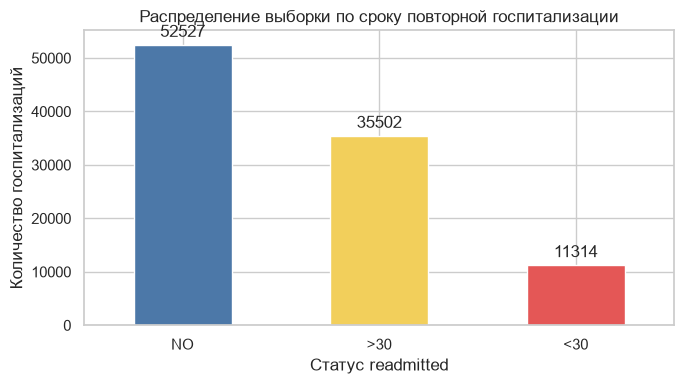

In [99]:
import matplotlib.pyplot as plt

sample_distribution = (
    modeling_data["readmitted"]
    .value_counts()
    .reindex(["NO", ">30", "<30"], fill_value=0)
    .rename_axis("readmitted")
    .to_frame("encounters")
)

ax = sample_distribution["encounters"].plot.bar(
    figsize=(7, 4),
    color=["#4C78A8", "#F2CF5B", "#E45756"],
    rot=0,
)
ax.set_title("Распределение выборки по сроку повторной госпитализации")
ax.set_xlabel("Статус readmitted")
ax.set_ylabel("Количество госпитализаций")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.tight_layout()
plt.show()

In [100]:
first_split = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
train_idx, temp_idx = next(
    first_split.split(modeling_data, groups=modeling_data["patient_nbr"])
)

train_data = modeling_data.iloc[train_idx].copy()
temp_data = modeling_data.iloc[temp_idx].copy()

second_split = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
validation_idx, test_idx = next(
    second_split.split(temp_data, groups=temp_data["patient_nbr"])
)

validation_data = temp_data.iloc[validation_idx].copy()
test_data = temp_data.iloc[test_idx].copy()

split_summary = pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "encounters": [len(train_data), len(validation_data), len(test_data)],
        "patients": [
            train_data["patient_nbr"].nunique(),
            validation_data["patient_nbr"].nunique(),
            test_data["patient_nbr"].nunique(),
        ],
        "target_rate_pct": [
            train_data["target_30d"].mean() * 100,
            validation_data["target_30d"].mean() * 100,
            test_data["target_30d"].mean() * 100,
        ],
    }
)
split_summary["target_rate_pct"] = split_summary["target_rate_pct"].round(2)

patient_sets = [
    set(train_data["patient_nbr"]),
    set(validation_data["patient_nbr"]),
    set(test_data["patient_nbr"]),
]
assert patient_sets[0].isdisjoint(patient_sets[1])
assert patient_sets[0].isdisjoint(patient_sets[2])
assert patient_sets[1].isdisjoint(patient_sets[2])

split_summary

,split,encounters,patients,target_rate_pct
0,train,69519,48993,11.39
1,validation,14911,10498,11.67
2,test,14913,10499,11.12


## 4. Одномерный анализ — train

,encounters,share_pct
target_30d,,
0,61603,88.61
1,7916,11.39


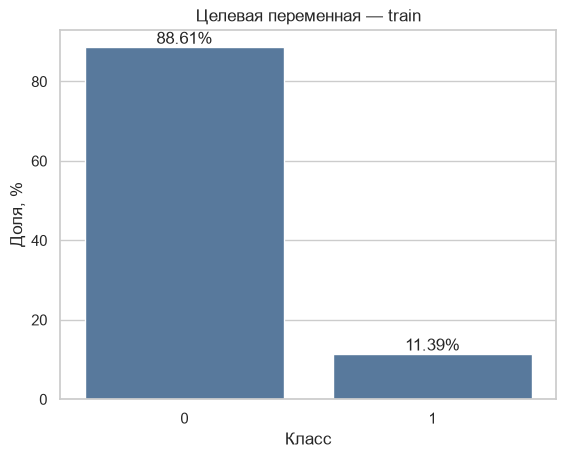

In [101]:
target_distribution = (
    train_data["target_30d"]
    .value_counts()
    .rename_axis("target_30d")
    .to_frame("encounters")
)
target_distribution["share_pct"] = (
    target_distribution["encounters"]
    .div(target_distribution["encounters"].sum())
    .mul(100)
    .round(2)
)

display(target_distribution)

ax = sns.barplot(
    data=target_distribution.reset_index(),
    x="target_30d",
    y="share_pct",
    color="#4C78A8",
)
ax.set(title="Целевая переменная — train", xlabel="Класс", ylabel="Доля, %")
ax.bar_label(ax.containers[0], fmt="%.2f%%")
plt.show()

In [102]:
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

train_data[numeric_features].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
time_in_hospital,69519.0,4.378731,2.965119,1.0,1.0,2.0,4.0,6.0,11.0,13.0,14.0
num_lab_procedures,69519.0,42.979214,19.527179,1.0,1.0,31.0,44.0,57.0,73.0,84.0,132.0
num_procedures,69519.0,1.333549,1.703705,0.0,0.0,0.0,1.0,2.0,5.0,6.0,6.0
num_medications,69519.0,15.994678,8.123759,1.0,3.0,10.0,15.0,20.0,31.0,43.0,81.0
number_outpatient,69519.0,0.364821,1.237123,0.0,0.0,0.0,0.0,0.0,2.0,5.0,40.0
number_emergency,69519.0,0.194292,0.938028,0.0,0.0,0.0,0.0,0.0,1.0,3.0,76.0
number_inpatient,69519.0,0.629368,1.249496,0.0,0.0,0.0,0.0,1.0,3.0,6.0,21.0
number_diagnoses,69519.0,7.396208,1.949862,1.0,2.0,6.0,8.0,9.0,9.0,9.0,16.0


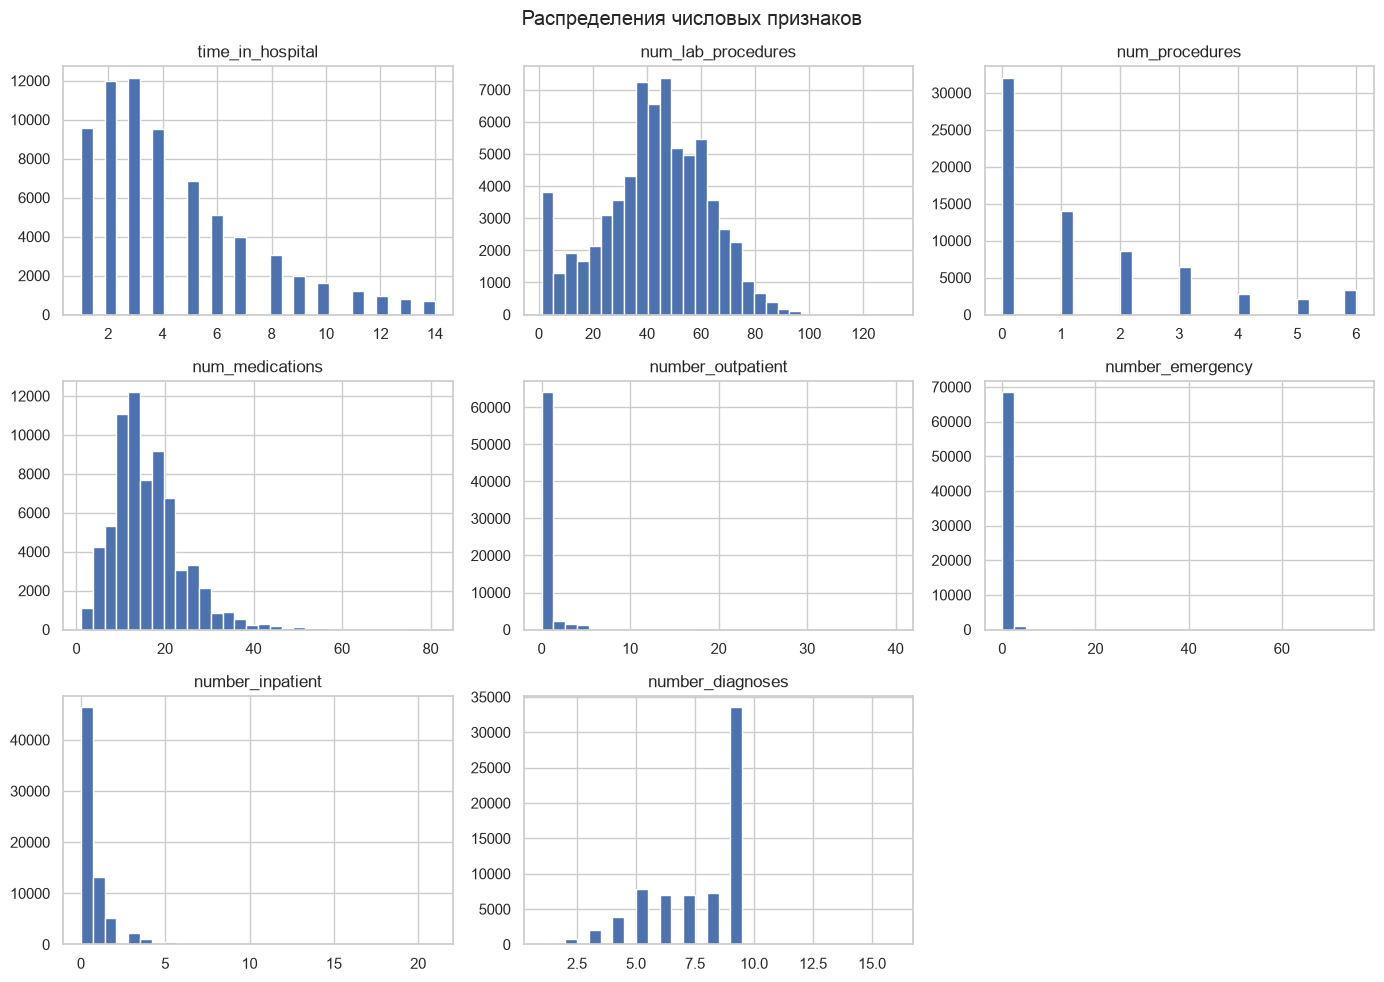

In [105]:
train_data[numeric_features].hist(figsize=(14, 10), bins=30)
plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.show()

### Вывод по распределениям числовых признаков

- Большинство числовых признаков имеют дискретное и асимметричное распределение.
- `time_in_hospital` имеет правый хвост: большинство значений небольшие, но встречаются более высокие.
- `number_outpatient` и `number_emergency` содержат много нулей и редкие экстремальные значения. Это характерно для счётчиков предыдущих обращений.
- `num_lab_procedures` имеет более равномерное распределение с центром примерно в районе 40–50 исследований.
- `number_diagnoses` сосредоточен преимущественно в диапазоне 6–9.

In [106]:
categorical_features = [
    "age",
    "gender",
    "race",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "medical_specialty",
    "A1Cresult",
    "max_glu_serum",
]

categorical_profile = pd.DataFrame(
    {
        "unique_values": train_data[categorical_features].nunique(dropna=False),
        "most_frequent": [
            train_data[column].mode(dropna=False).iloc[0]
            for column in categorical_features
        ],
    }
)
categorical_profile

,unique_values,most_frequent
age,10,[70-80)
gender,3,Female
race,6,Caucasian
admission_type_id,8,1
discharge_disposition_id,21,1
admission_source_id,17,7
medical_specialty,72,NaN
A1Cresult,4,NaN
max_glu_serum,4,NaN


## 5. Связи с целевой переменной — train

In [108]:
numeric_by_target = train_data.groupby("target_30d")[numeric_features].median().T
numeric_by_target.columns = ["target_0_median", "target_1_median"]

numeric_by_target

,target_0_median,target_1_median
time_in_hospital,4.0,4.0
num_lab_procedures,44.0,45.0
num_procedures,1.0,1.0
num_medications,15.0,16.0
number_outpatient,0.0,0.0
number_emergency,0.0,0.0
number_inpatient,0.0,1.0
number_diagnoses,8.0,9.0


In [14]:
def target_rate_by_category(frame: pd.DataFrame, feature: str) -> pd.DataFrame:
    return (
        frame.assign(category=frame[feature].fillna("Not measured"))
        .groupby("category", dropna=False)["target_30d"]
        .agg(encounters="size", readmitted_30d="sum", readmission_rate="mean")
        .assign(readmission_rate_pct=lambda table: table["readmission_rate"].mul(100).round(2))
        .sort_values("encounters", ascending=False)
    )

display(target_rate_by_category(train_data, "A1Cresult"))
display(target_rate_by_category(train_data, "max_glu_serum"))

,encounters,readmitted_30d,readmission_rate,readmission_rate_pct
category,,,,
Not measured,57737,6744,0.116806,11.68
>8,5727,562,0.098132,9.81
Norm,3418,351,0.102692,10.27
>7,2637,259,0.098218,9.82


,encounters,readmitted_30d,readmission_rate,readmission_rate_pct
category,,,,
Not measured,65940,7467,0.113239,11.32
Norm,1806,206,0.114064,11.41
>200,992,125,0.126008,12.60
>300,781,118,0.151088,15.11


In [15]:
laboratory_status = (
    train_data.assign(
        a1c_status=np.where(train_data["A1Cresult"].isna(), "Not measured", "Measured"),
        glucose_status=np.where(train_data["max_glu_serum"].isna(), "Not measured", "Measured"),
    )
    .groupby(["glucose_status", "a1c_status"])["target_30d"]
    .agg(encounters="size", readmitted_30d="sum", readmission_rate="mean")
)
laboratory_status["readmission_rate_pct"] = (
    laboratory_status["readmission_rate"].mul(100).round(2)
)
laboratory_status

encounters  readmitted_30d  readmission_rate  \
glucose_status a1c_status                                                   
Measured       Measured             199              28          0.140704   
               Not measured        3380             421          0.124556   
Not measured   Measured           11583            1144          0.098765   
               Not measured       54357            6323          0.116324   

                             readmission_rate_pct  
glucose_status a1c_status                          
Measured       Measured                     14.07  
               Not measured                 12.46  
Not measured   Measured                      9.88  
               Not measured                 11.63

## 6. Корреляции — train

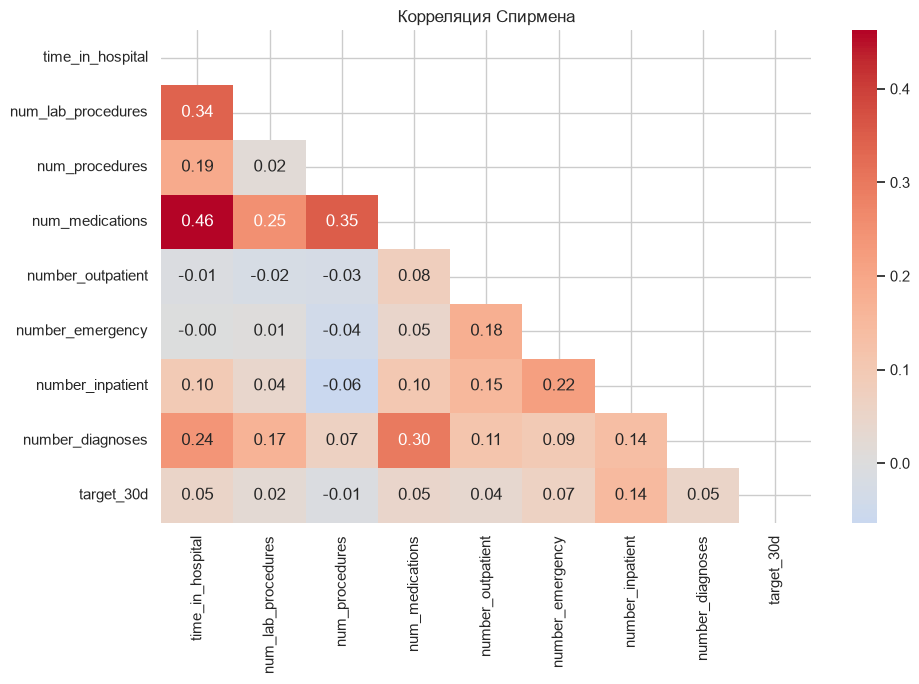

In [109]:
correlation = train_data[numeric_features + ["target_30d"]].corr(method="spearman")
mask = np.triu(np.ones_like(correlation, dtype=bool))

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Корреляция Спирмена")
plt.tight_layout()
plt.show()

### Вывод по корреляциям

- Сильных корреляций между числовыми признаками и `target_30d` не обнаружено.
- Наиболее заметная связь с повторной госпитализацией наблюдается у `number_inpatient` - **0.14**. Чем больше предыдущих стационарных обращений, тем несколько выше вероятность повторной госпитализации.
- Корреляции `number_emergency` (**0.07**), `time_in_hospital`, `num_medications` и `number_diagnoses` (около **0.05**) слабые.
- `num_lab_procedures` и `num_procedures` почти не имеют отдельной монотонной связи с целевой переменной.
- Между самими признаками есть умеренные связи: `time_in_hospital` связан с `num_medications` (**0.46**) и `num_lab_procedures` (**0.34**), а `num_procedures` - с `num_medications` (**0.35**).
- Корреляций выше 0.5 нет, поэтому выраженной мультиколлинеарности среди выбранных числовых признаков не видно.


## 7. Выводы

- `weight`: удалить — 96.86% пропусков.
- Смерть/хоспис: исключить из целевой популяции.
- `patient_nbr`: использовать только для группового split.
- `A1Cresult` и `max_glu_serum`: оставить до ablation-теста.
- Далее: обработка редких категорий и baseline-модель.

In [110]:
modeling_dataset = pd.concat(
    [
        train_data.assign(split="train"),
        validation_data.assign(split="validation"),
        test_data.assign(split="test"),
    ]
).sort_index()

assert len(modeling_dataset) == len(modeling_data)
assert modeling_dataset["encounter_id"].is_unique
assert set(modeling_dataset["split"]) == {"train", "validation", "test"}

output_path = project_root / "data" / "interim" / "modeling_dataset.parquet"
output_path.parent.mkdir(parents=True, exist_ok=True)

modeling_dataset.to_parquet(output_path, index=False)

print(f"Датасет сохранён: {output_path}")
print(modeling_dataset["split"].value_counts())

Датасет сохранён: /Users/mac/PycharmProjects/hospital-readmission-ml/data/interim/modeling_dataset.parquet
split
train         69519
test          14913
validation    14911
Name: count, dtype: int64
